In [1]:
#%pip install matplotlib seaborn

In [2]:
# import sys
# !{sys.executable} -m pip install matplotlib seaborn

In [3]:
import pandas as pd
date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']

listings_raw = pd.read_csv('data/listings_clean.csv', parse_dates=date_columns)
listings = listings_raw.copy()

listings.shape
listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 4574 entries, 0 to 4573
Data columns (total 73 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   id                                            4574 non-null   int64         
 1   listing_url                                   4574 non-null   str           
 2   scrape_id                                     4574 non-null   int64         
 3   last_scraped                                  4574 non-null   datetime64[us]
 4   source                                        1704 non-null   str           
 5   name                                          4574 non-null   str           
 6   description                                   4519 non-null   str           
 7   picture_url                                   4574 non-null   str           
 8   host_id                                       4574 non-null   int64         
 9

## Setup Visualization:
1) import matplot from matplotlib
2) import seaborn
3) setup theme

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

Task1:
How many listings(count) for range of reviews:
1) in x axis list range of reviews
2) in y axis number of listings
3) Use histogram chart type
4) listings['number_of_reviews]

(array([3.297e+03, 5.250e+02, 2.160e+02, 1.210e+02, 7.700e+01, 6.400e+01,
        5.100e+01, 4.300e+01, 3.200e+01, 2.400e+01, 2.200e+01, 1.700e+01,
        9.000e+00, 1.100e+01, 1.100e+01, 1.200e+01, 9.000e+00, 4.000e+00,
        6.000e+00, 5.000e+00, 5.000e+00, 2.000e+00, 1.000e+00, 0.000e+00,
        3.000e+00, 1.000e+00, 1.000e+00, 0.000e+00, 1.000e+00, 1.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 2.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([   0.  ,   25.86,   51.72,   77.58,  103.44,  129.3 ,  155.16,
         181.02,  206.88,  232.74,  258.6 ,  284.46,  310.32,  336.18,
         362.04,  387.9 ,  413.76,  439.62,  465.48,  491.34,  517.2 ,
         543.06,  568.92,  594.78,  620.64,  646.5 ,  672.36,  698.22,
         724.08,  749.94,  775.8 ,  801.66,  827.52,  853.38,  879.24,
         905.1 ,  930

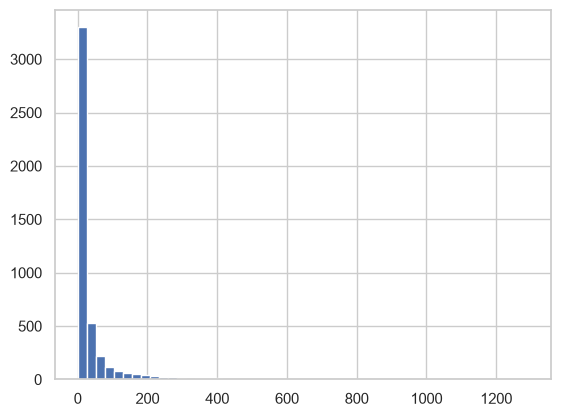

In [5]:
fig,ax = plt.subplots()
ax.hist(listings['number_of_reviews'].dropna(),bins=50)


1293


Text(0, 0.5, 'number of listings')

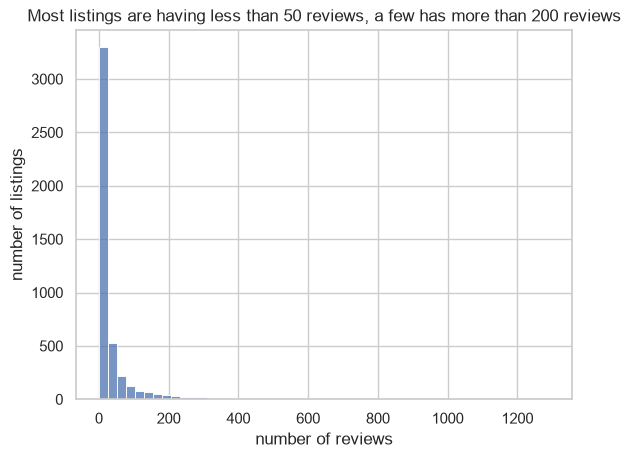

In [6]:
fig, ax = plt.subplots()
sns.histplot(listings,x='number_of_reviews',bins=50,ax=ax)
# Max review (the x axis extension)
print(listings['number_of_reviews'].max())
ax.set_title('Most listings are having less than 50 reviews, a few has more than 200 reviews')
ax.set_xlabel('number of reviews')
ax.set_ylabel('number of listings')


Observation of above:
Few listings has more than 3000 reviews
most of the listings has less than 500 reviews
But this does not say about mean or typical listing reviews

Task2:
mean, median, iqr,upper fence, draw histogram differenciate with different colors

36.0 9.0 2.0 29.0 69.5
69.5 582


Text(0, 0.5, 'number of listings')

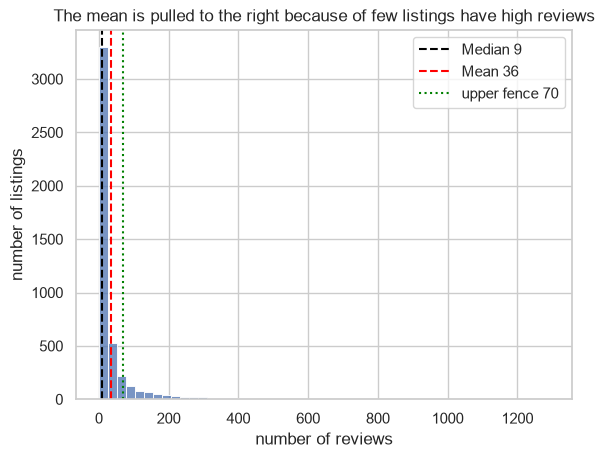

In [7]:
mean = listings['number_of_reviews'].mean().round(0)
median = listings['number_of_reviews'].median()
q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
iqr = q3 - q1

upper = q3 + 1.5 * iqr
print(mean,median,q1,q3,upper)

listings['reviews_outlier'] = listings['number_of_reviews'] > upper
print(upper,listings['reviews_outlier'].sum())

fig, ax = plt.subplots()
sns.histplot(listings,x='number_of_reviews',bins=50,ax=ax
             )
ax.axvline(median,color='black',linestyle='--',label=f'Median {median:,.0f}')
ax.axvline(mean,color='red',linestyle='--',label=f'Mean {mean:,.0f}')
ax.axvline(upper,color='green',linestyle=':',label=f'upper fence {upper:,.0f}')
ax.legend()

ax.set_title('The mean is pulled to the right because of few listings have high reviews')
ax.set_xlabel('number of reviews')
ax.set_ylabel('number of listings')


Observation:
upper fence moved out due to few listing has more reviews

Task 3: The histogram for with and without outliers
1. We already know the outliers in column 'reviews_outlier'
2. Draw 2 subplots in the same ax
3. Draw without outliers in letft and with outliers on the right

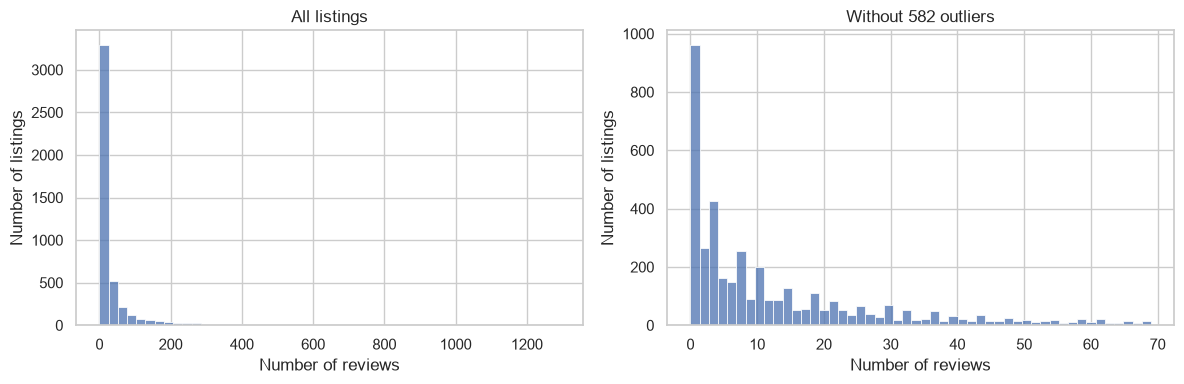

In [8]:
fig, axes = plt.subplots(1,2,figsize=(12,4))

sns.histplot(data=listings, x='number_of_reviews',bins=50,ax=axes[0])
sns.histplot(data=listings[~listings['reviews_outlier']],x='number_of_reviews',bins=50,ax=axes[1])

axes[0].set_title('All listings')
axes[1].set_title('Without 582 outliers')

for ax in axes:
    ax.set_xlabel('Number of reviews')
    ax.set_ylabel('Number of listings')

plt.tight_layout()
plt.show()

Observation of above chart:
In left: With all listings. the number of review spread is dragged upto 1200
In right: without outliers contains listings upuntill upper fence. The spread of number of reviews runs upto 70.
This picture helps to clarify to understand the spread of listings with smaller review spread.

Task 4:
The boxplot for number of reviews for two room types(Entire home/apt and private room)
1) Derive the data to be shown in chart
2) Use boxplot 
3) Set limit for y axis
4) Set title as your observation of outcome


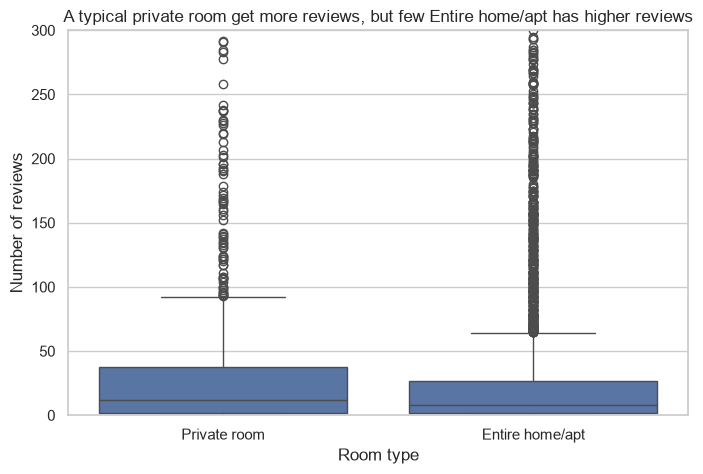

In [9]:
two_types = listings[listings['room_type'].isin(['Entire home/apt','Private room'])]

fig, ax = plt.subplots(figsize=(8,5))

sns.boxplot(data=two_types,x='room_type',y='number_of_reviews',ax=ax)
ax.set_title('A typical private room get more reviews, but few Entire home/apt has higher reviews')
ax.set_xlabel('Room type')
ax.set_ylabel('Number of reviews')
ax.set_ylim(0,300)
plt.show()


Observation:
In the inital outcome:
 the spread is very much concentrated in lower side and boundries are not clear and start is not 0. So now I am going to set ylimit to 300 and see the chart

 The chart is wider with figsize=10,3

After update:
Median of Private room is higher than Entire home/apt. (A typical private room get more reviews, few Entire home/apt has higher reviews)
Private room IQR is bigger.( Private room has more typical reviews, Entire home/apt has more outliers)
loer fence not shown here as it was negative so it starts from 0